**Data Validation & Exploration**

```text
dataset/
└──Plantvillage/
    ├── Potato___Healthy/
    ├── Potato___Early_blight/
    └── Potato___Late_blight/


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

In [3]:
!ls

'archive (1).zip'   drive   sample_data


In [4]:
!unzip "archive (1).zip" -d dataset

Archive:  archive (1).zip
  inflating: dataset/PlantVillage/Potato___Early_blight/001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG  
  inflating: dataset/PlantVillage/Potato___Early_blight/002a55fb-7a3d-4a3a-aca8-ce2d5ebc6925___RS_Early.B 8170.JPG  
  inflating: dataset/PlantVillage/Potato___Early_blight/009c8c31-f22d-4ffd-8f16-189c6f06c577___RS_Early.B 7885.JPG  
  inflating: dataset/PlantVillage/Potato___Early_blight/00d8f10f-5038-4e0f-bb58-0b885ddc0cc5___RS_Early.B 8722.JPG  
  inflating: dataset/PlantVillage/Potato___Early_blight/0182e991-97f0-4805-a1f7-6e1b4306d518___RS_Early.B 7015.JPG  
  inflating: dataset/PlantVillage/Potato___Early_blight/02578b86-b234-4ac0-9bc3-691b5610e2bf___RS_Early.B 7562.JPG  
  inflating: dataset/PlantVillage/Potato___Early_blight/0267d4ca-522e-4ca0-b1a2-ce925e5b54a2___RS_Early.B 7020.JPG  
  inflating: dataset/PlantVillage/Potato___Early_blight/028f9b73-142f-499a-9c7b-d7c1ed5e5506___RS_Early.B 8546.JPG  
  inflating: dataset/PlantVillage/Pota

In [5]:
DATASET_PATH = "dataset/PlantVillage"


classes = [
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight"
]


print("Dataset Path:", DATASET_PATH)
print("Classes:", classes)

Dataset Path: dataset/PlantVillage
Classes: ['Potato___healthy', 'Potato___Early_blight', 'Potato___Late_blight']


In [6]:
print("Folders inside dataset/PlantVillage:")
print(os.listdir("dataset/PlantVillage"))


Folders inside dataset/PlantVillage:
['Potato___healthy', 'Potato___Late_blight', 'Potato___Early_blight']


In [7]:
import os

for cls in classes:
    class_path = os.path.join(DATASET_PATH, cls)
    print(f"{cls} existing →", os.path.exists(class_path))


Potato___healthy existing → True
Potato___Early_blight existing → True
Potato___Late_blight existing → True


In [8]:
image_count = {}

for cls in classes:
    class_path = os.path.join(DATASET_PATH, cls)
    image_count[cls] = len(os.listdir(class_path))

image_count


{'Potato___healthy': 152,
 'Potato___Early_blight': 1000,
 'Potato___Late_blight': 1000}

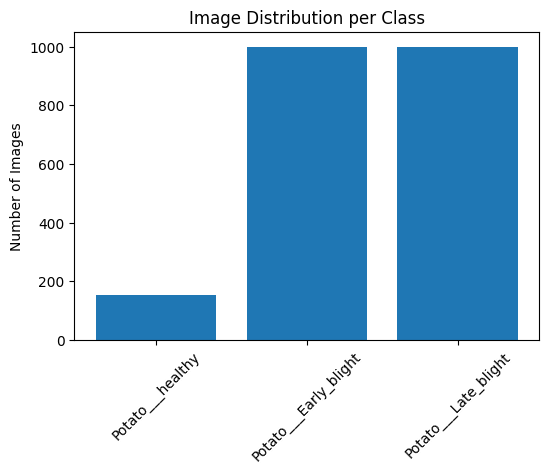

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.bar(image_count.keys(), image_count.values())
plt.title("Image Distribution per Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()


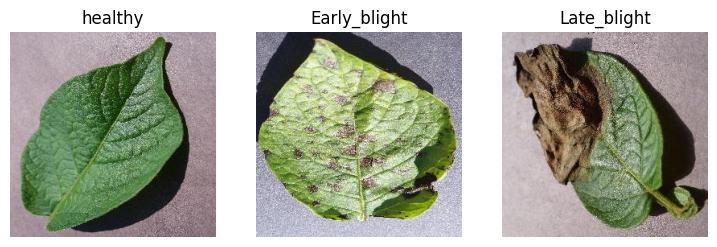

In [10]:
#(Visual Inspection)

from PIL import Image
import random

plt.figure(figsize=(9,3))

for i, cls in enumerate(classes):
    class_path = os.path.join(DATASET_PATH, cls)
    img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, img_name)

    img = Image.open(img_path)

    plt.subplot(1,3,i+1)
    plt.imshow(img)
    plt.title(cls.replace("Potato___", ""))
    plt.axis("off")

plt.show()


In [12]:
#(Image Dimensions)

image_shapes = []

for cls in classes:
    cls_path = os.path.join(DATASET_PATH, cls)
    for img_name in os.listdir(cls_path)[:20]:
        img_path = os.path.join(cls_path, img_name)
        img = cv2.imread(img_path)
        if img is not None:
            image_shapes.append(img.shape)

print(Counter(image_shapes))


Counter({(256, 256, 3): 60})


In [13]:
#(Data Integrity)

corrupted_images = []

for cls in classes:
    cls_path = os.path.join(DATASET_PATH, cls)
    for img_name in os.listdir(cls_path):
        img_path = os.path.join(cls_path, img_name)
        img = cv2.imread(img_path)
        if img is None:
            corrupted_images.append(img_path)

print("Corrupted Images:", len(corrupted_images))


Corrupted Images: 0


**Preprocessing**

In [14]:
import os
import numpy as np
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [15]:
IMAGE_SIZE = 224
DATASET_PATH = "dataset/PlantVillage"

classes = [
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight"
]


In [16]:
images = []
labels = []

for cls in classes:
    class_path = os.path.join(DATASET_PATH, cls)

    for img_name in tqdm(os.listdir(class_path), desc=f"Loading {cls}"):
        img_path = os.path.join(class_path, img_name)

        try:
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))

            images.append(img)
            labels.append(cls)
        except:
            pass


Loading Potato___Late_blight: 100%|██████████| 1000/1000 [00:00<00:00, 1127.12it/s]


In [17]:
X = np.array(images)
y = np.array(labels)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)


Images shape: (2152, 224, 224, 3)
Labels shape: (2152,)


In [18]:
X = X / 255.0


In [19]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

print("Class mapping:")
for cls, idx in zip(encoder.classes_, range(len(encoder.classes_))):
    print(cls, "→", idx)


Class mapping:
Potato___Early_blight → 0
Potato___Late_blight → 1
Potato___healthy → 2


In [20]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Train size:", X_train.shape)
print("Validation size:", X_val.shape)


Train size: (1721, 224, 224, 3)
Validation size: (431, 224, 224, 3)


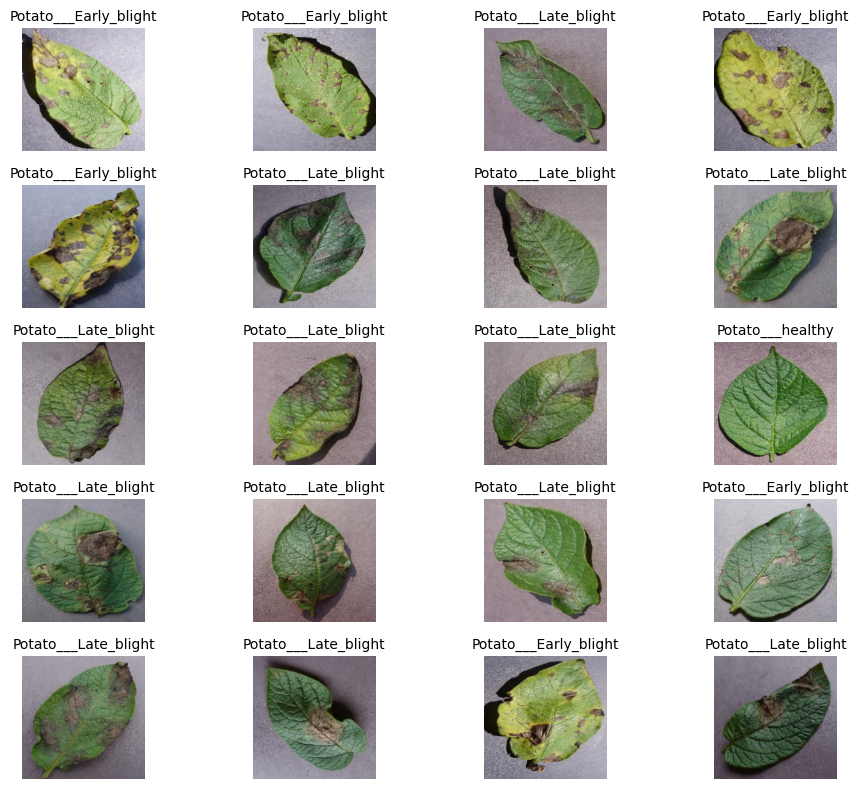

In [21]:
plt.figure(figsize=(10,8))

for i in range(20):
    plt.subplot(5,4,i+1)
    plt.imshow(X_train[i])
    plt.title(encoder.inverse_transform([y_train[i]])[0])
    plt.title(encoder.inverse_transform([y_train[i]])[0], fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()


In [22]:
import pandas as pd

y_names = encoder.inverse_transform(y_train)

print(pd.Series(y_names).value_counts())

Potato___Early_blight    800
Potato___Late_blight     800
Potato___healthy         121
Name: count, dtype: int64


**Data Splitting**

In [24]:
import os
import random
import shutil

DATASET_PATH = "dataset/PlantVillage"
OUTPUT_PATH = "dataset_split"

classes = [
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight"
]


In [25]:
splits = ["train", "val", "test"]

for split in splits:
    for cls in classes:
        os.makedirs(os.path.join(OUTPUT_PATH, split, cls), exist_ok=True)


In [26]:
train_ratio = 0.7
val_ratio = 0.15
test_ratio = 0.15


In [27]:
for cls in classes:
    class_path = os.path.join(DATASET_PATH, cls)
    images = os.listdir(class_path)
    random.shuffle(images)

    total = len(images)
    train_end = int(total * train_ratio)
    val_end = train_end + int(total * val_ratio)

    train_imgs = images[:train_end]
    val_imgs = images[train_end:val_end]
    test_imgs = images[val_end:]

    for img in train_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(OUTPUT_PATH, "train", cls, img)
        )

    for img in val_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(OUTPUT_PATH, "val", cls, img)
        )

    for img in test_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(OUTPUT_PATH, "test", cls, img)
        )


In [28]:
for split in splits:
    print(f"\n{split.upper()}:")
    for cls in classes:
        path = os.path.join(OUTPUT_PATH, split, cls)
        print(cls, ":", len(os.listdir(path)))



TRAIN:
Potato___healthy : 106
Potato___Early_blight : 700
Potato___Late_blight : 700

VAL:
Potato___healthy : 22
Potato___Early_blight : 150
Potato___Late_blight : 150

TEST:
Potato___healthy : 24
Potato___Early_blight : 150
Potato___Late_blight : 150


**Data Augmentation**

In [29]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os


In [30]:
train_dir = "/content/dataset_split/train"
val_dir   = "/content/dataset_split/val"
test_dir  = "/content/dataset_split/test"



In [31]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)


In [ ]:
!ls /content


'archive (1).zip'   dataset   dataset_split   drive   sample_data


In [ ]:
!ls /content/dataset_split


test  train  val


In [ ]:
!ls /content/dataset_split/train


Potato___Early_blight  Potato___healthy  Potato___Late_blight


In [32]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)


Found 1506 images belonging to 3 classes.


**CNN**

In [33]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [ ]:
# feature_extractor = Sequential([

#     Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
#     MaxPooling2D(2,2),

#     Conv2D(64, (3,3), activation='relu'),
#     MaxPooling2D(2,2),

#     Conv2D(128, (3,3), activation='relu'),
#     MaxPooling2D(2,2),

#     Flatten(),

#     Dense(128, activation='relu')
# ])



/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

val_datagen = ImageDataGenerator(rescale=1./255)


In [35]:
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 322 images belonging to 3 classes.


In [36]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_dir  = "/content/dataset_split/test"

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)



Found 324 images belonging to 3 classes.


In [ ]:
# feature_extractor.trainable = False

In [ ]:
# X_train_features = feature_extractor.predict(train_generator)
# y_train = train_generator.classes

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


48/48 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step


In [ ]:
# X_val_features = feature_extractor.predict(val_generator)
# y_val = val_generator.classes

11/11 ━━━━━━━━━━━━━━━━━━━━ 10s 841ms/step


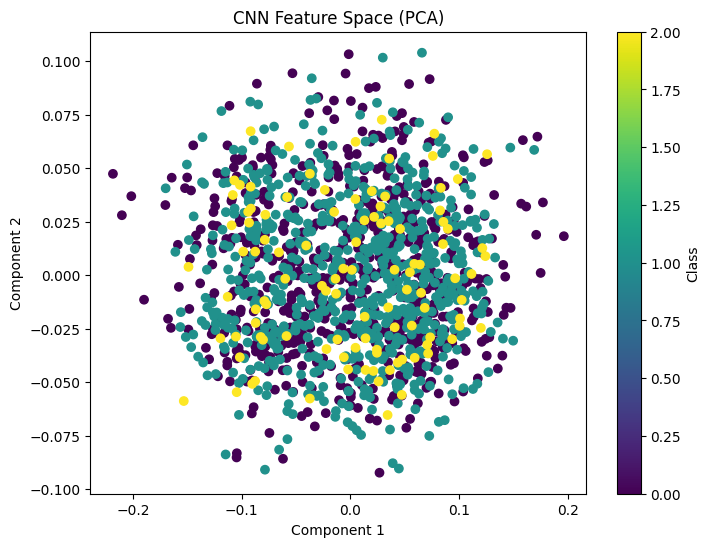

In [ ]:
# from sklearn.decomposition import PCA

# pca = PCA(n_components=2)
# X_reduced = pca.fit_transform(X_train_features)

# plt.figure(figsize=(8,6))
# plt.scatter(X_reduced[:,0], X_reduced[:,1], c=y_train, cmap='viridis')
# plt.colorbar(label='Class')
# plt.title("CNN Feature Space (PCA)")
# plt.xlabel("Component 1")
# plt.ylabel("Component 2")
# plt.show()


In [37]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler



In [39]:
datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

In [40]:
train_generator = datagen.flow_from_directory(
    '/content/dataset_split/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)


val_generator = datagen.flow_from_directory(
    '/content/dataset_split/val',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)


test_generator = datagen.flow_from_directory(
    '/content/dataset_split/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 1506 images belonging to 3 classes.
Found 322 images belonging to 3 classes.
Found 324 images belonging to 3 classes.


**CNN**

In [41]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
x = base_model.output
x = GlobalAveragePooling2D()(x)
feature_extractor = Model(inputs=base_model.input, outputs=x)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [42]:
print("Training features are being extracted")
X_train = feature_extractor.predict(train_generator, verbose=1)
print("Val features are being extracted")
X_val = feature_extractor.predict(val_generator, verbose=1)
print("testing features are being extracted")
X_test = feature_extractor.predict(test_generator, verbose=1)

Training features are being extracted


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


48/48 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step
Val features are being extracted
11/11 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step
testing features are being extracted
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step


In [43]:
y_train = train_generator.classes
y_val = val_generator.classes
y_test = test_generator.classes

In [44]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

**SVM**

In [45]:

svm_model = SVC(kernel='rbf', C=10, probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

SVC(C=10, probability=True, random_state=42)

In [46]:
print("  results  ")
y_val_pred = svm_model.predict(X_val_scaled)
print(f"Validation Accuracy: {accuracy_score(y_val, y_val_pred):.4f}")

y_test_pred = svm_model.predict(X_test_scaled)
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")

print("\nClassification Report (Test):")
print(classification_report(y_test, y_test_pred))

  results  
Validation Accuracy: 0.9596
Test Accuracy: 0.9753

Classification Report (Test):
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       150
           1       0.96      0.99      0.97       150
           2       1.00      0.92      0.96        24

    accuracy                           0.98       324
   macro avg       0.98      0.96      0.97       324
weighted avg       0.98      0.98      0.98       324



In [47]:
from sklearn.model_selection import cross_val_score

print("is calculated Cross-Validation......")

scores = cross_val_score(svm_model, X_train_scaled, y_train, cv=5)

print("Results of the five experiments:", scores)
print(f"Final average accuracy: {scores.mean():.4f}")

is calculated Cross-Validation......
Results of the five experiments: [0.98344371 0.99003322 0.97009967 0.9833887  0.97674419]
Final average accuracy: 0.9807


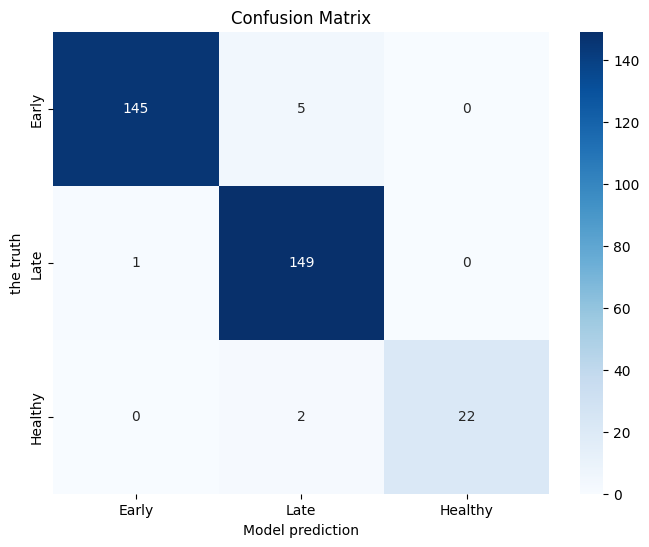

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Early', 'Late', 'Healthy'],
            yticklabels=['Early', 'Late', 'Healthy'])
plt.xlabel('Model prediction')
plt.ylabel('the truth')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# # --- تصفير وإعادة بناء كل شيء لضمان الصحة ---
# import numpy as np
# from sklearn.metrics import accuracy_score

# # 1. التأكد من أن المولدات مضبوطة (بدون خلط)
# # لضمان أن ترتيب الصور يطابق ترتيب اللواصق
# train_generator.reset()
# val_generator.reset()
# test_generator.reset()

# # 2. الحصول على اللواصق الصحيحة (المرتبة)
# y_train_clean = train_generator.classes
# y_val_clean   = val_generator.classes
# y_test_clean  = test_generator.classes

# # 3. التأكد من استخراج الميزات بنفس الترتيب
# # (قد يستغرق دقيقة لكنه ضروري للتأكد)
# print("1. جاري استخراج الميزات من جديد لضمان الترتيب...")
# X_train_clean = feature_extractor.predict(train_generator, verbose=1)
# X_val_clean   = feature_extractor.predict(val_generator, verbose=0)
# X_test_clean  = feature_extractor.predict(test_generator, verbose=0)

# # 4. توحيد البيانات
# print("2. جاري توحيد البيانات (Scaling)...")
# scaler_clean = StandardScaler()
# X_train_clean_scaled = scaler_clean.fit_transform(X_train_clean)
# X_val_clean_scaled   = scaler_clean.transform(X_val_clean)
# X_test_clean_scaled  = scaler_clean.transform(X_test_clean)

# # 5. تدريب SVM
# print("3. جاري تدريب المودل...")
# svm_final = SVC(kernel='rbf', C=10, probability=True, random_state=42)
# svm_final.fit(X_train_clean_scaled, y_train_clean)

# # 6. حساب الدقة النهائية
# print("4. حساب النتائج...")

# # دقة التدريب
# train_pred = svm_final.predict(X_train_clean_scaled)
# acc_train = accuracy_score(y_train_clean, train_pred)

# # دقة التحقق
# val_pred = svm_final.predict(X_val_clean_scaled)
# acc_val = accuracy_score(y_val_clean, val_pred)

# # دقة الاختبار
# test_pred = svm_final.predict(X_test_clean_scaled)
# acc_test = accuracy_score(y_test_clean, test_pred)

# print("-" * 30)
# print(f"✅ Training Accuracy:   {acc_train*100:.2f}%")
# print(f"✅ Validation Accuracy: {acc_val*100:.2f}%")
# print(f"✅ Test Accuracy:       {acc_test*100:.2f}%")
# print("-" * 30)

# if abs(acc_train - acc_test) < 0.05:
#     print("🌟 النتيجة: المودل ممتاز ومتوازن (No Overfitting)")
# else:
#     print("⚠️ النتيجة: يوجد فرق كبير، راجع البيانات")

1. جاري استخراج الميزات من جديد لضمان الترتيب...
48/48 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step
2. جاري توحيد البيانات (Scaling)...
3. جاري تدريب المودل...
4. حساب النتائج...
------------------------------
✅ Training Accuracy:   100.00%
✅ Validation Accuracy: 96.58%
✅ Test Accuracy:       96.91%
------------------------------
🌟 النتيجة: المودل ممتاز ومتوازن (No Overfitting)


In [52]:
import joblib
import os
from tensorflow.keras.models import save_model

# 1. حفظ مستخرج الميزات (MobileNetV2)
feature_extractor.save('feature_extractor.h5')

# 2. حفظ المصنف (SVM)
joblib.dump(svm_model, 'svm_model.pkl')

# 3. حفظ الـ Scaler (ضروري جداً لتوحيد الأرقام)
joblib.dump(scaler, 'scaler.pkl')

print("✅ تم الحفظ! قم بتنزيل الملفات الثلاثة: feature_extractor.h5, svm_model.pkl, scaler.pkl")

✅ تم الحفظ! قم بتنزيل الملفات الثلاثة: feature_extractor.h5, svm_model.pkl, scaler.pkl


In [56]:
import os
import shutil

save_path = '/content/drive/MyDrive/My_Kaggle_Data'
os.makedirs(save_path, exist_ok=True)

source_file = 'archive (1).zip'

shutil.copy(source_file, save_path)

print(f"saved {save_path}")

saved /content/drive/MyDrive/My_Kaggle_Data
